# load library

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

 # EDA

In [8]:
df = pd.read_csv('dermatology_database.csv')
print(df.dtypes)
print(df.isnull().sum())
print(df.info())
print(df.head())
print(df.describe())


erythema                                int64
scaling                                 int64
definite_borders                        int64
itching                                 int64
koebner_phenomenon                      int64
polygonal_papules                       int64
follicular_papules                      int64
oral_mucosal_involvement                int64
knee_and_elbow_involvement              int64
scalp_involvement                       int64
family_history                          int64
melanin_incontinence                    int64
eosinophils_infiltrate                  int64
PNL_infiltrate                          int64
fibrosis_papillary_dermis               int64
exocytosis                              int64
acanthosis                              int64
hyperkeratosis                          int64
parakeratosis                           int64
clubbing_rete_ridges                    int64
elongation_rete_ridges                  int64
thinning_suprapapillary_epidermis 

C:\Users\evans\AppData\Local\Temp\ipykernel_22148\2183187948.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = 'class', y=col, ax=ax, palette='Set3', legend = True)
C:\Users\evans\AppData\Local\Temp\ipykernel_22148\2183187948.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = 'class', y=col, ax=ax, palette='Set3', legend = True)
C:\Users\evans\AppData\Local\Temp\ipykernel_22148\2183187948.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = 'class', y=col, ax=ax, palette='Set3', legend = True)
C

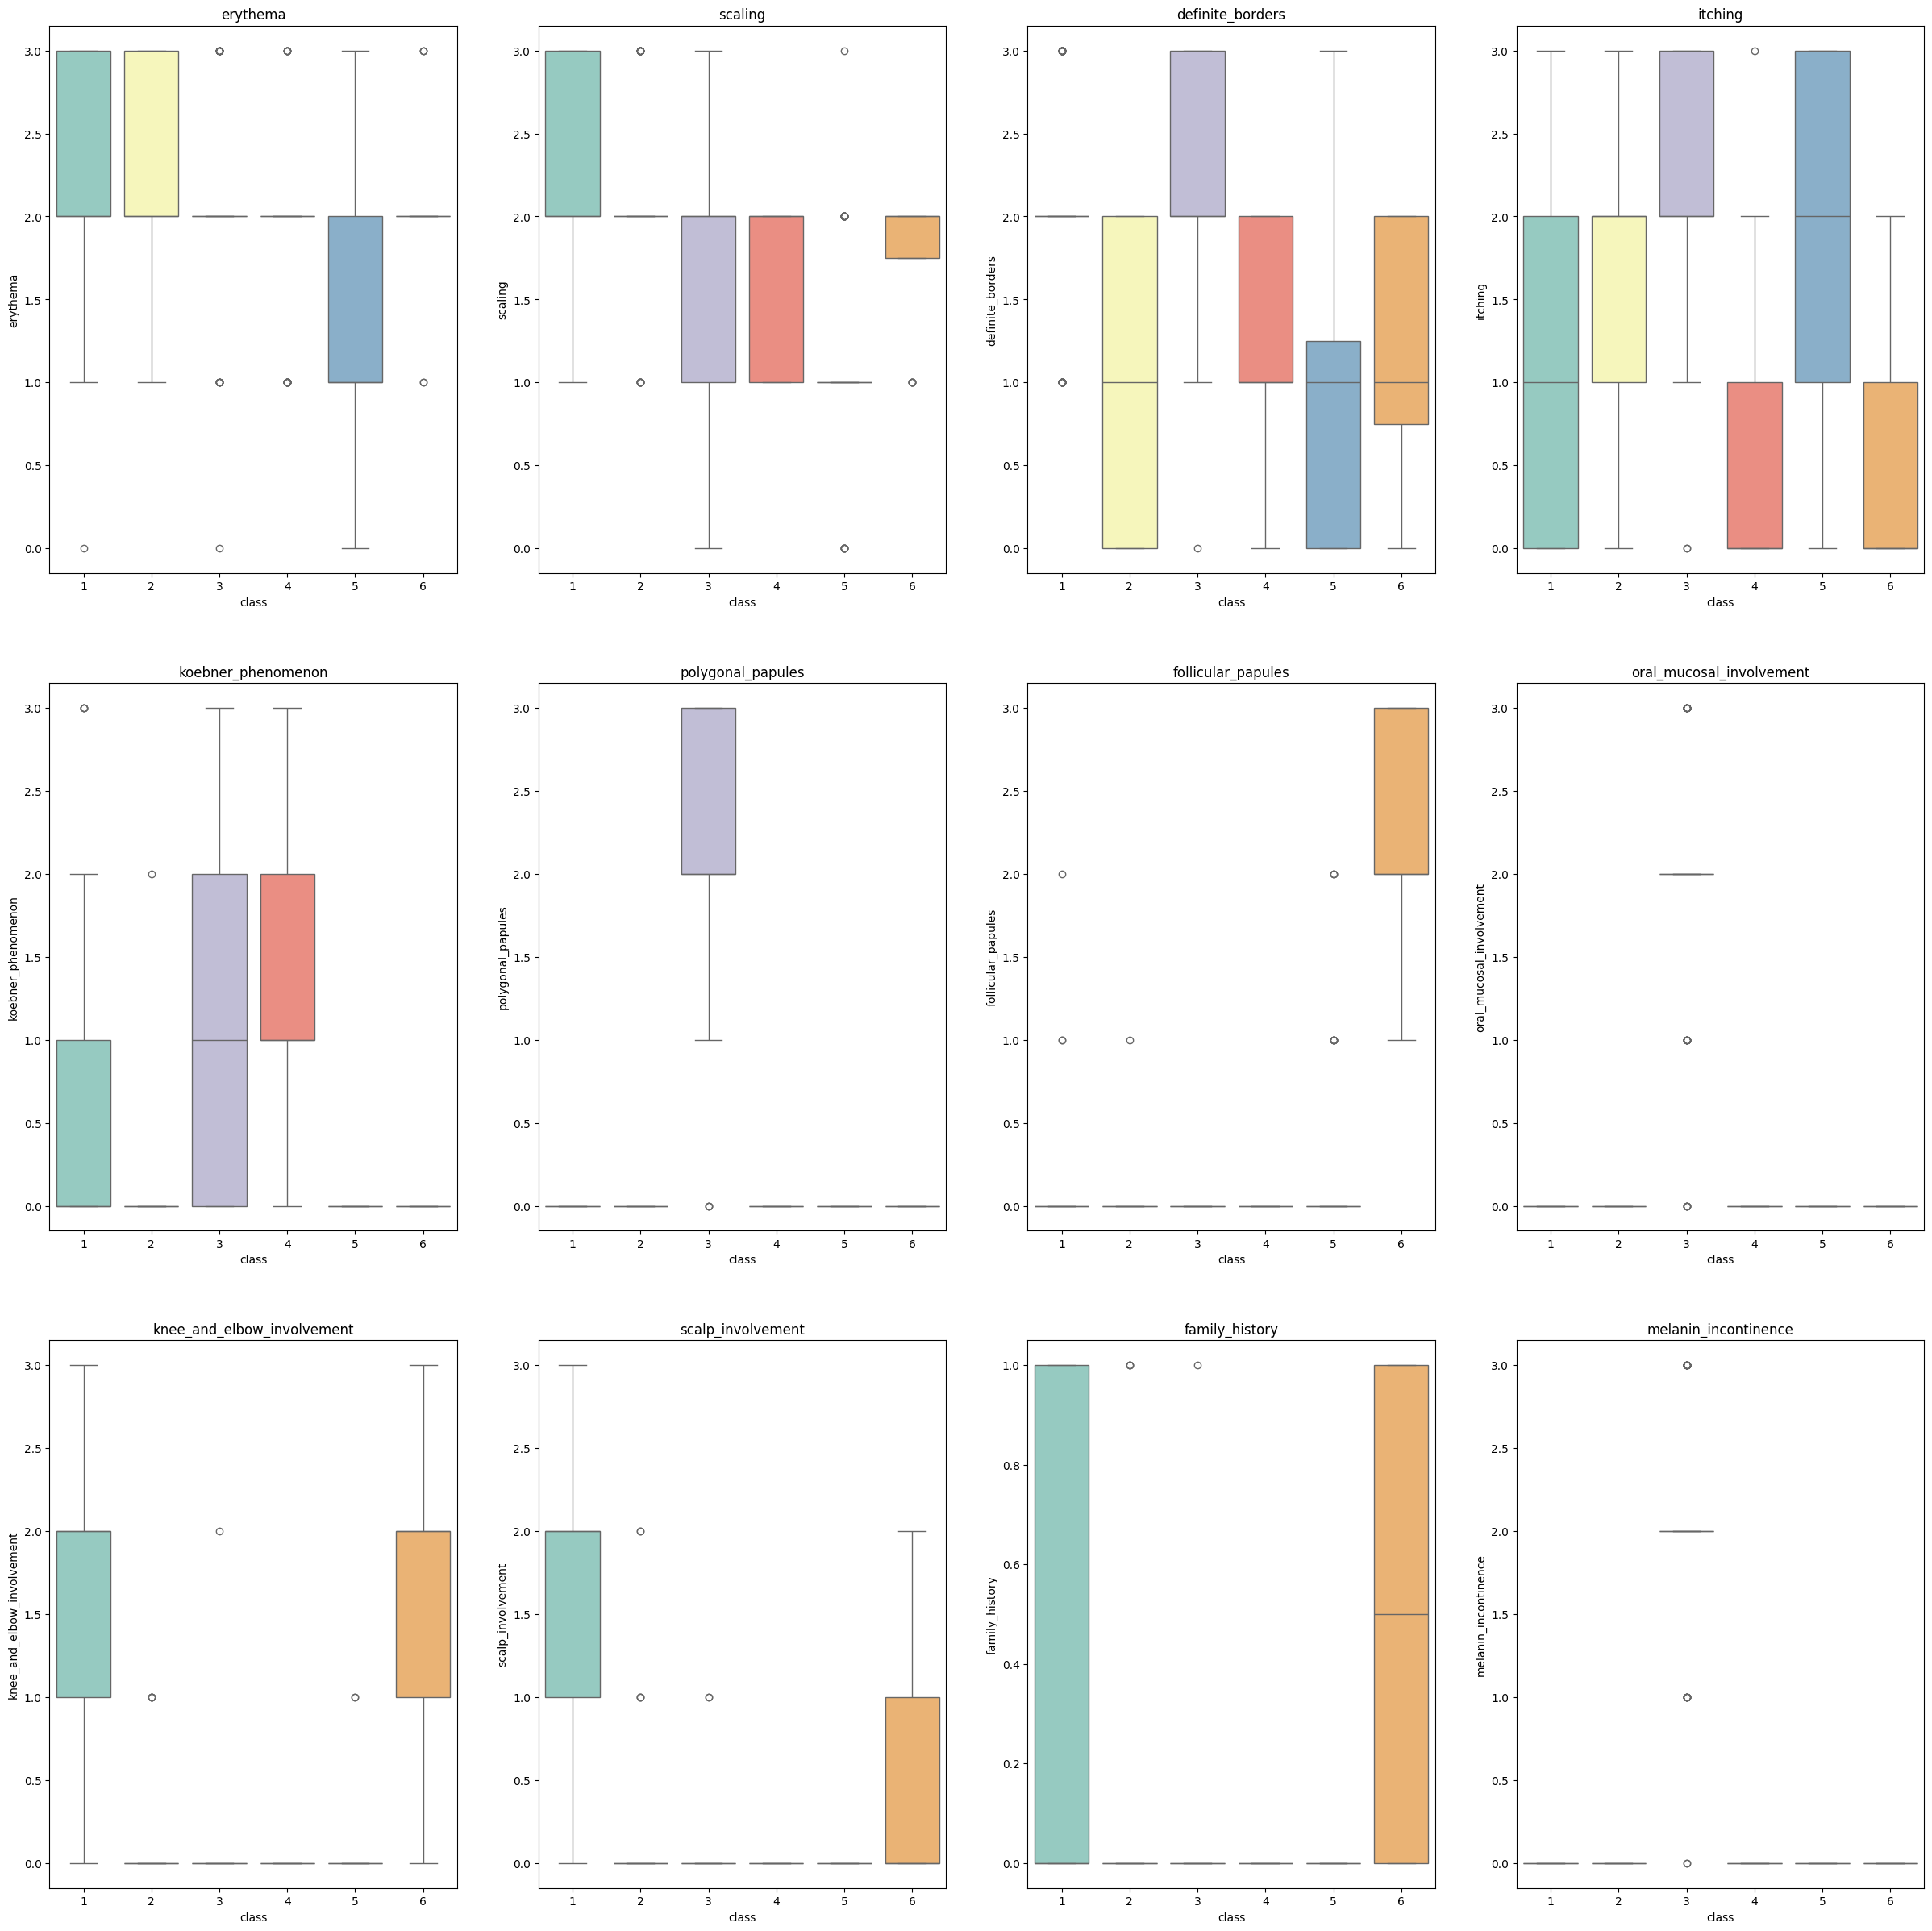

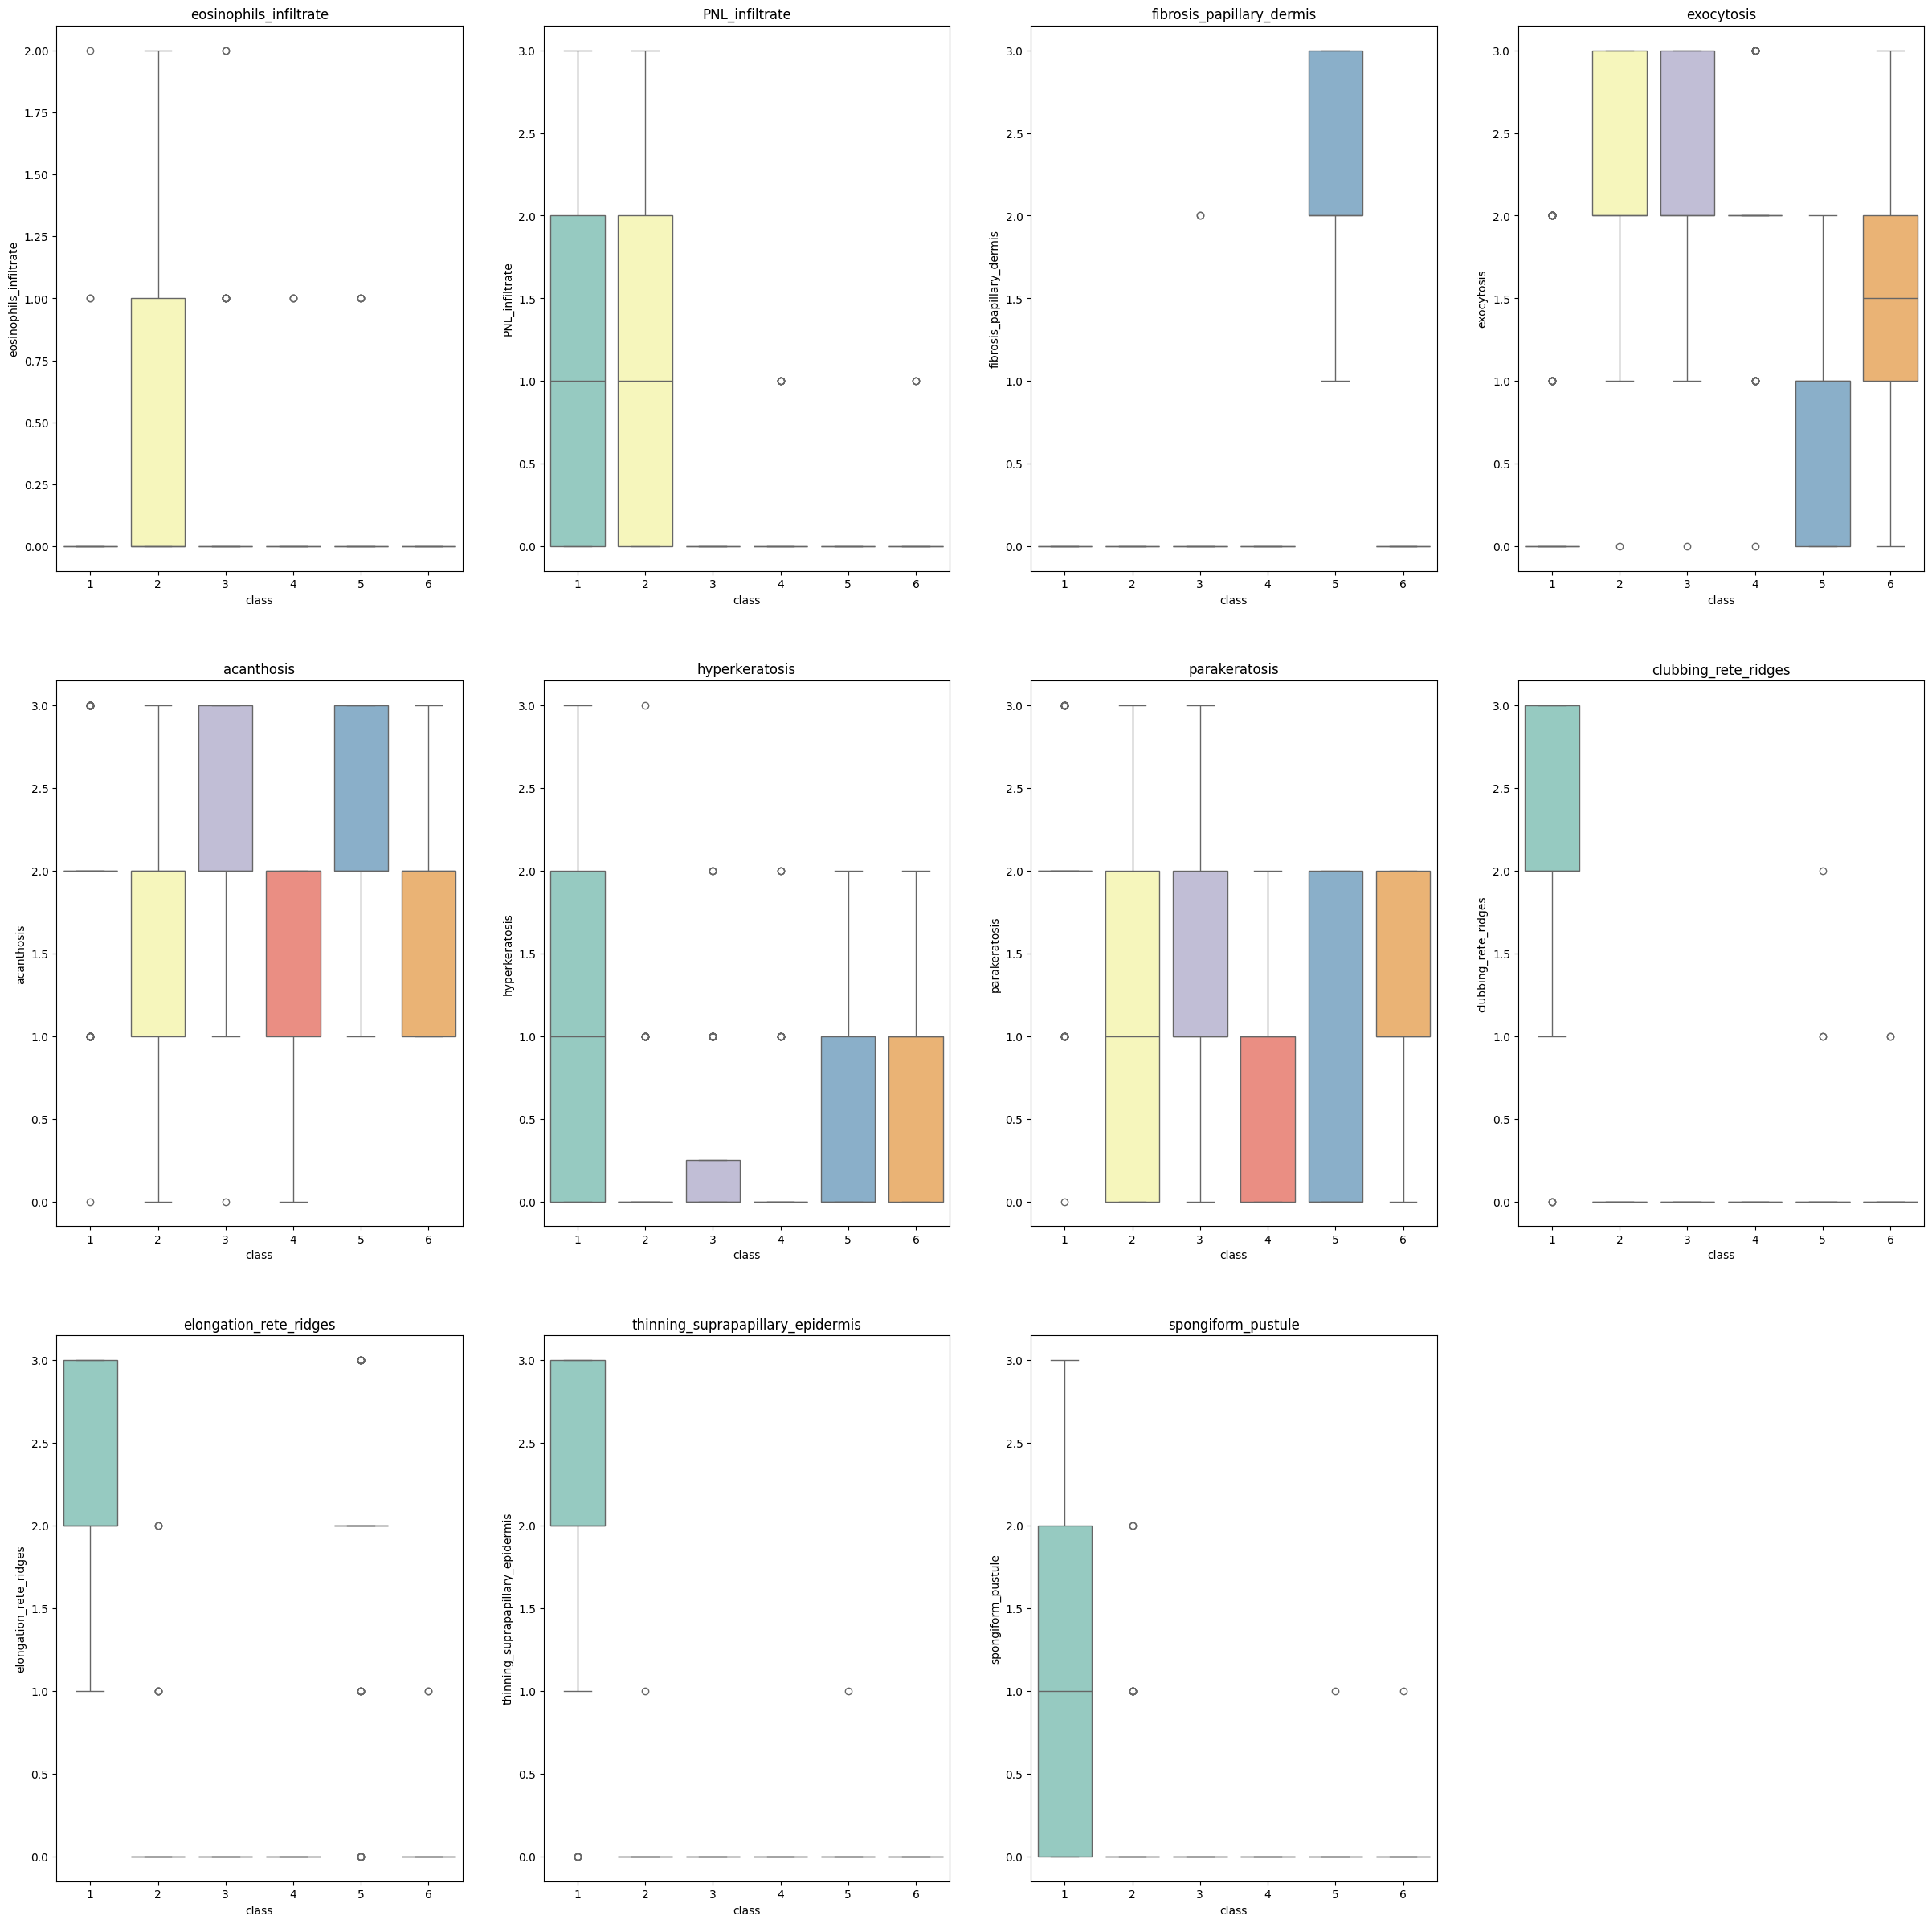

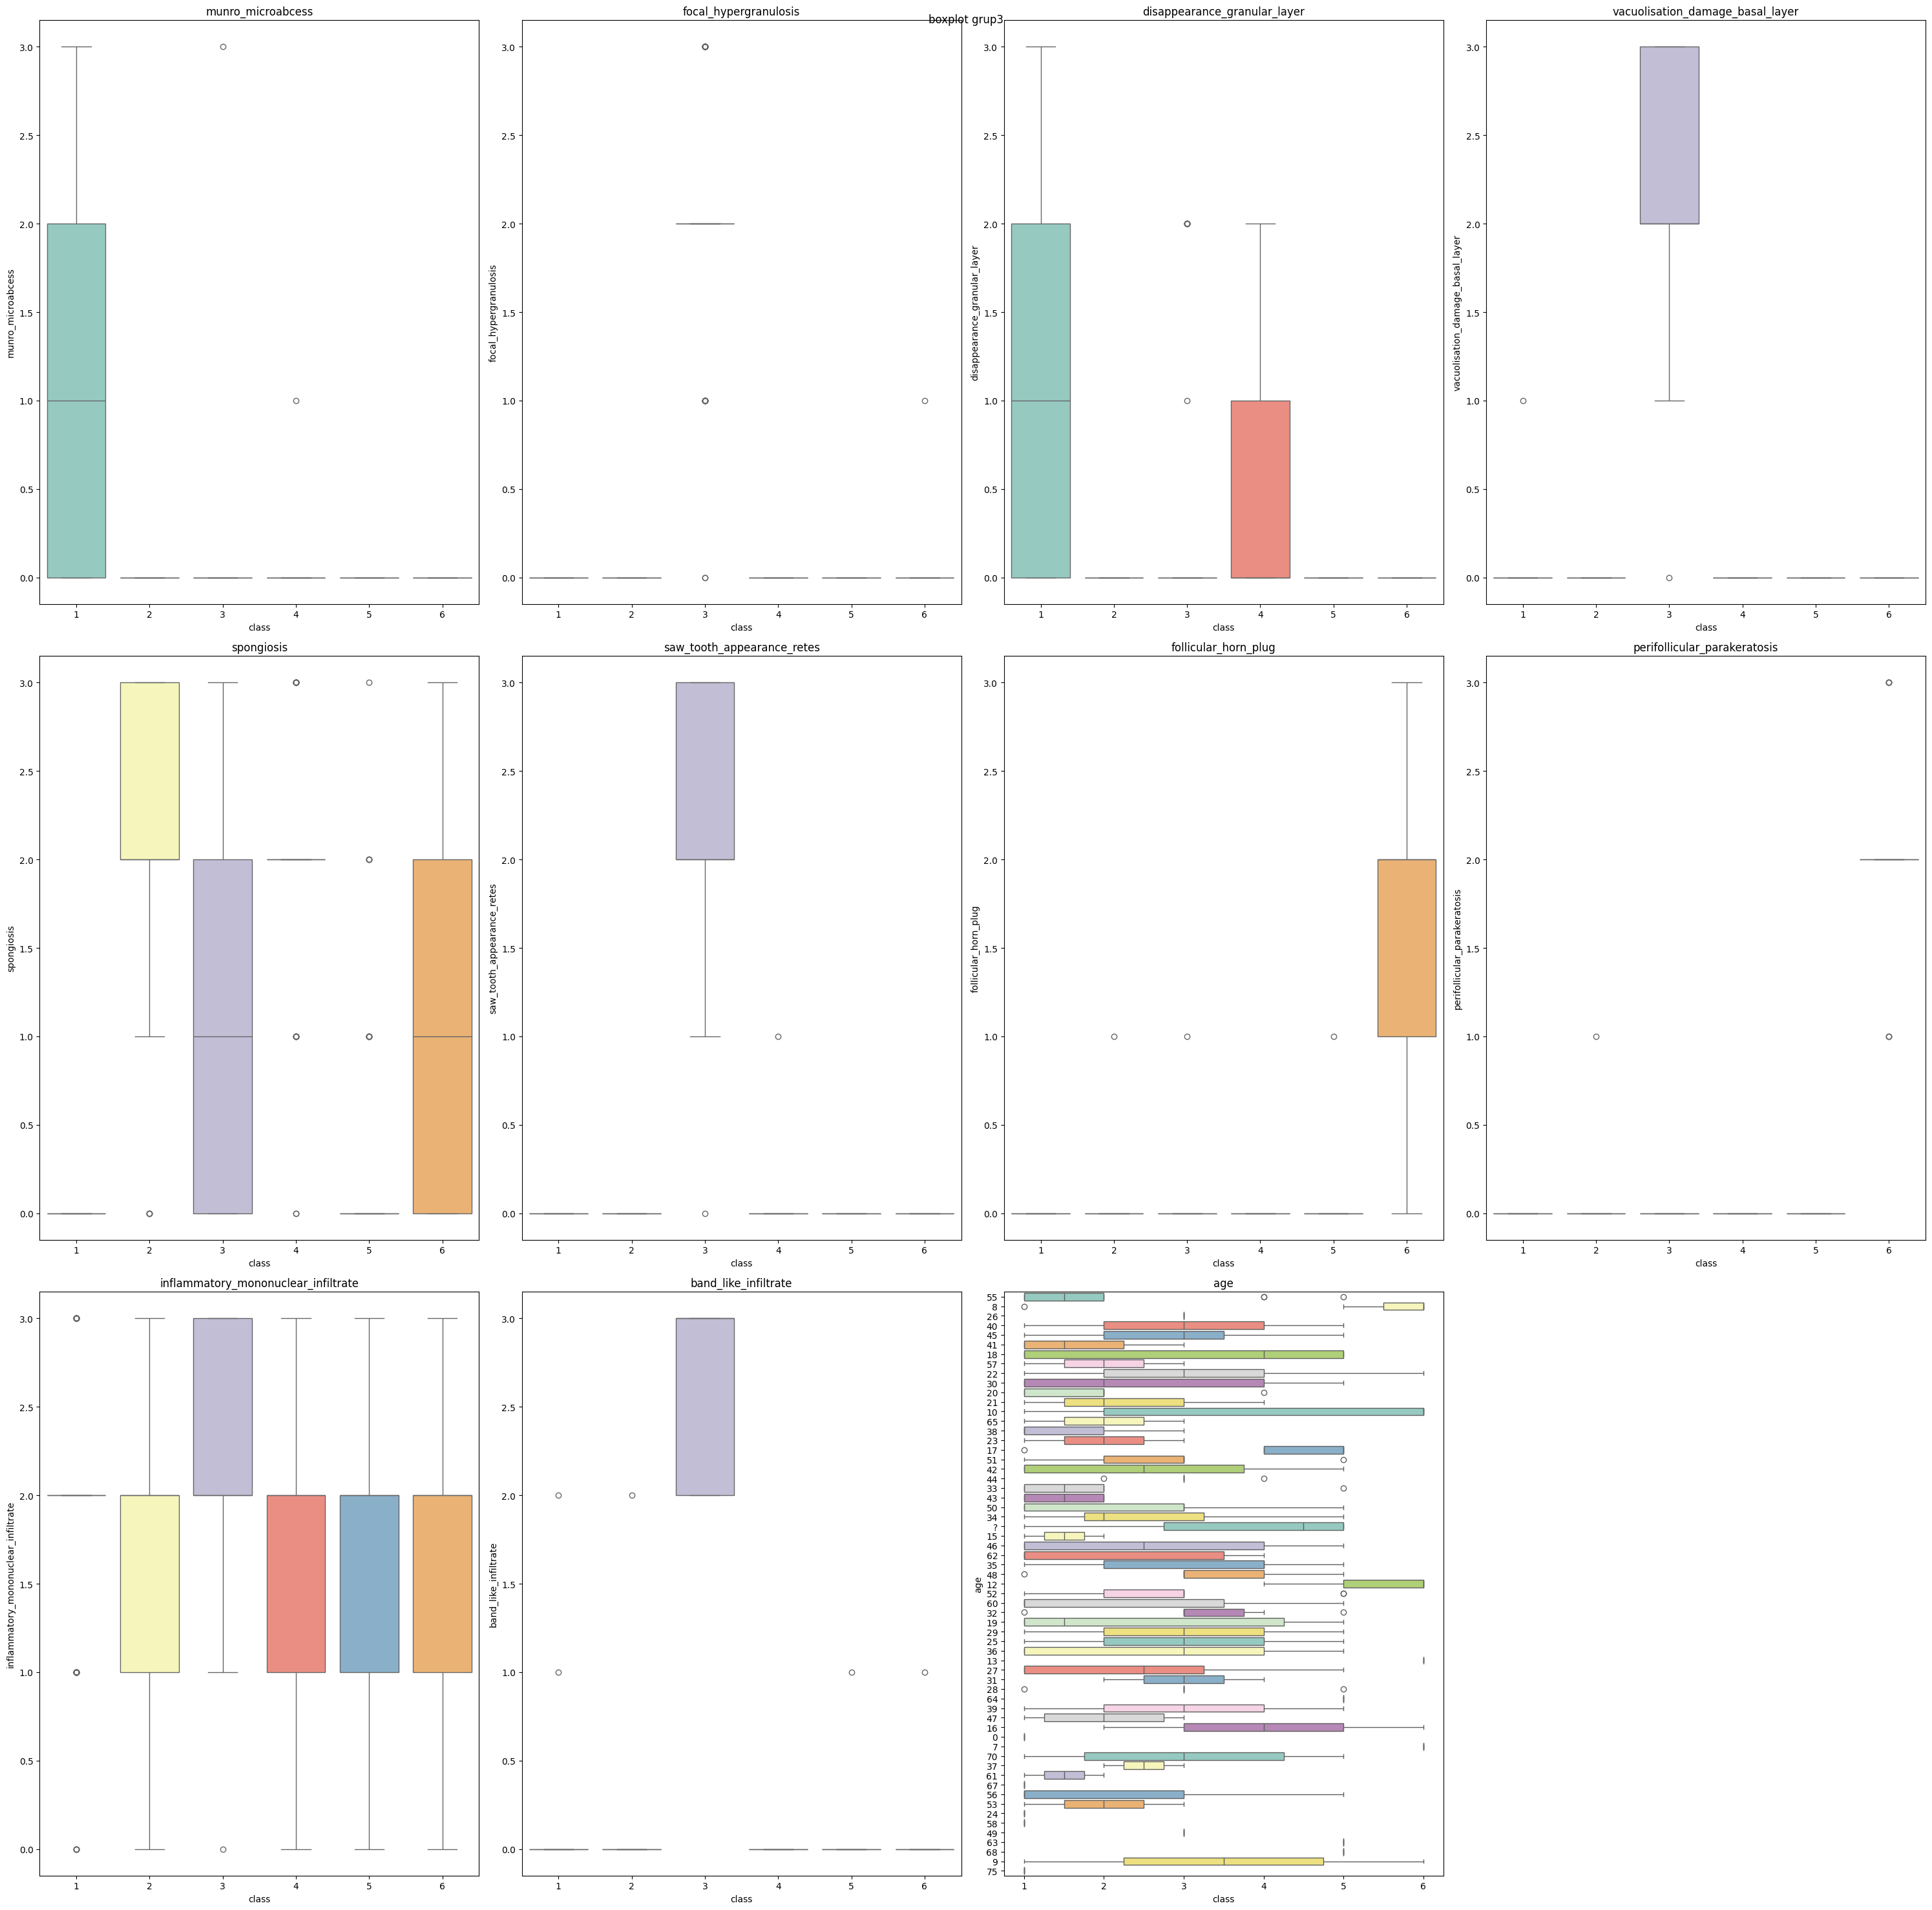

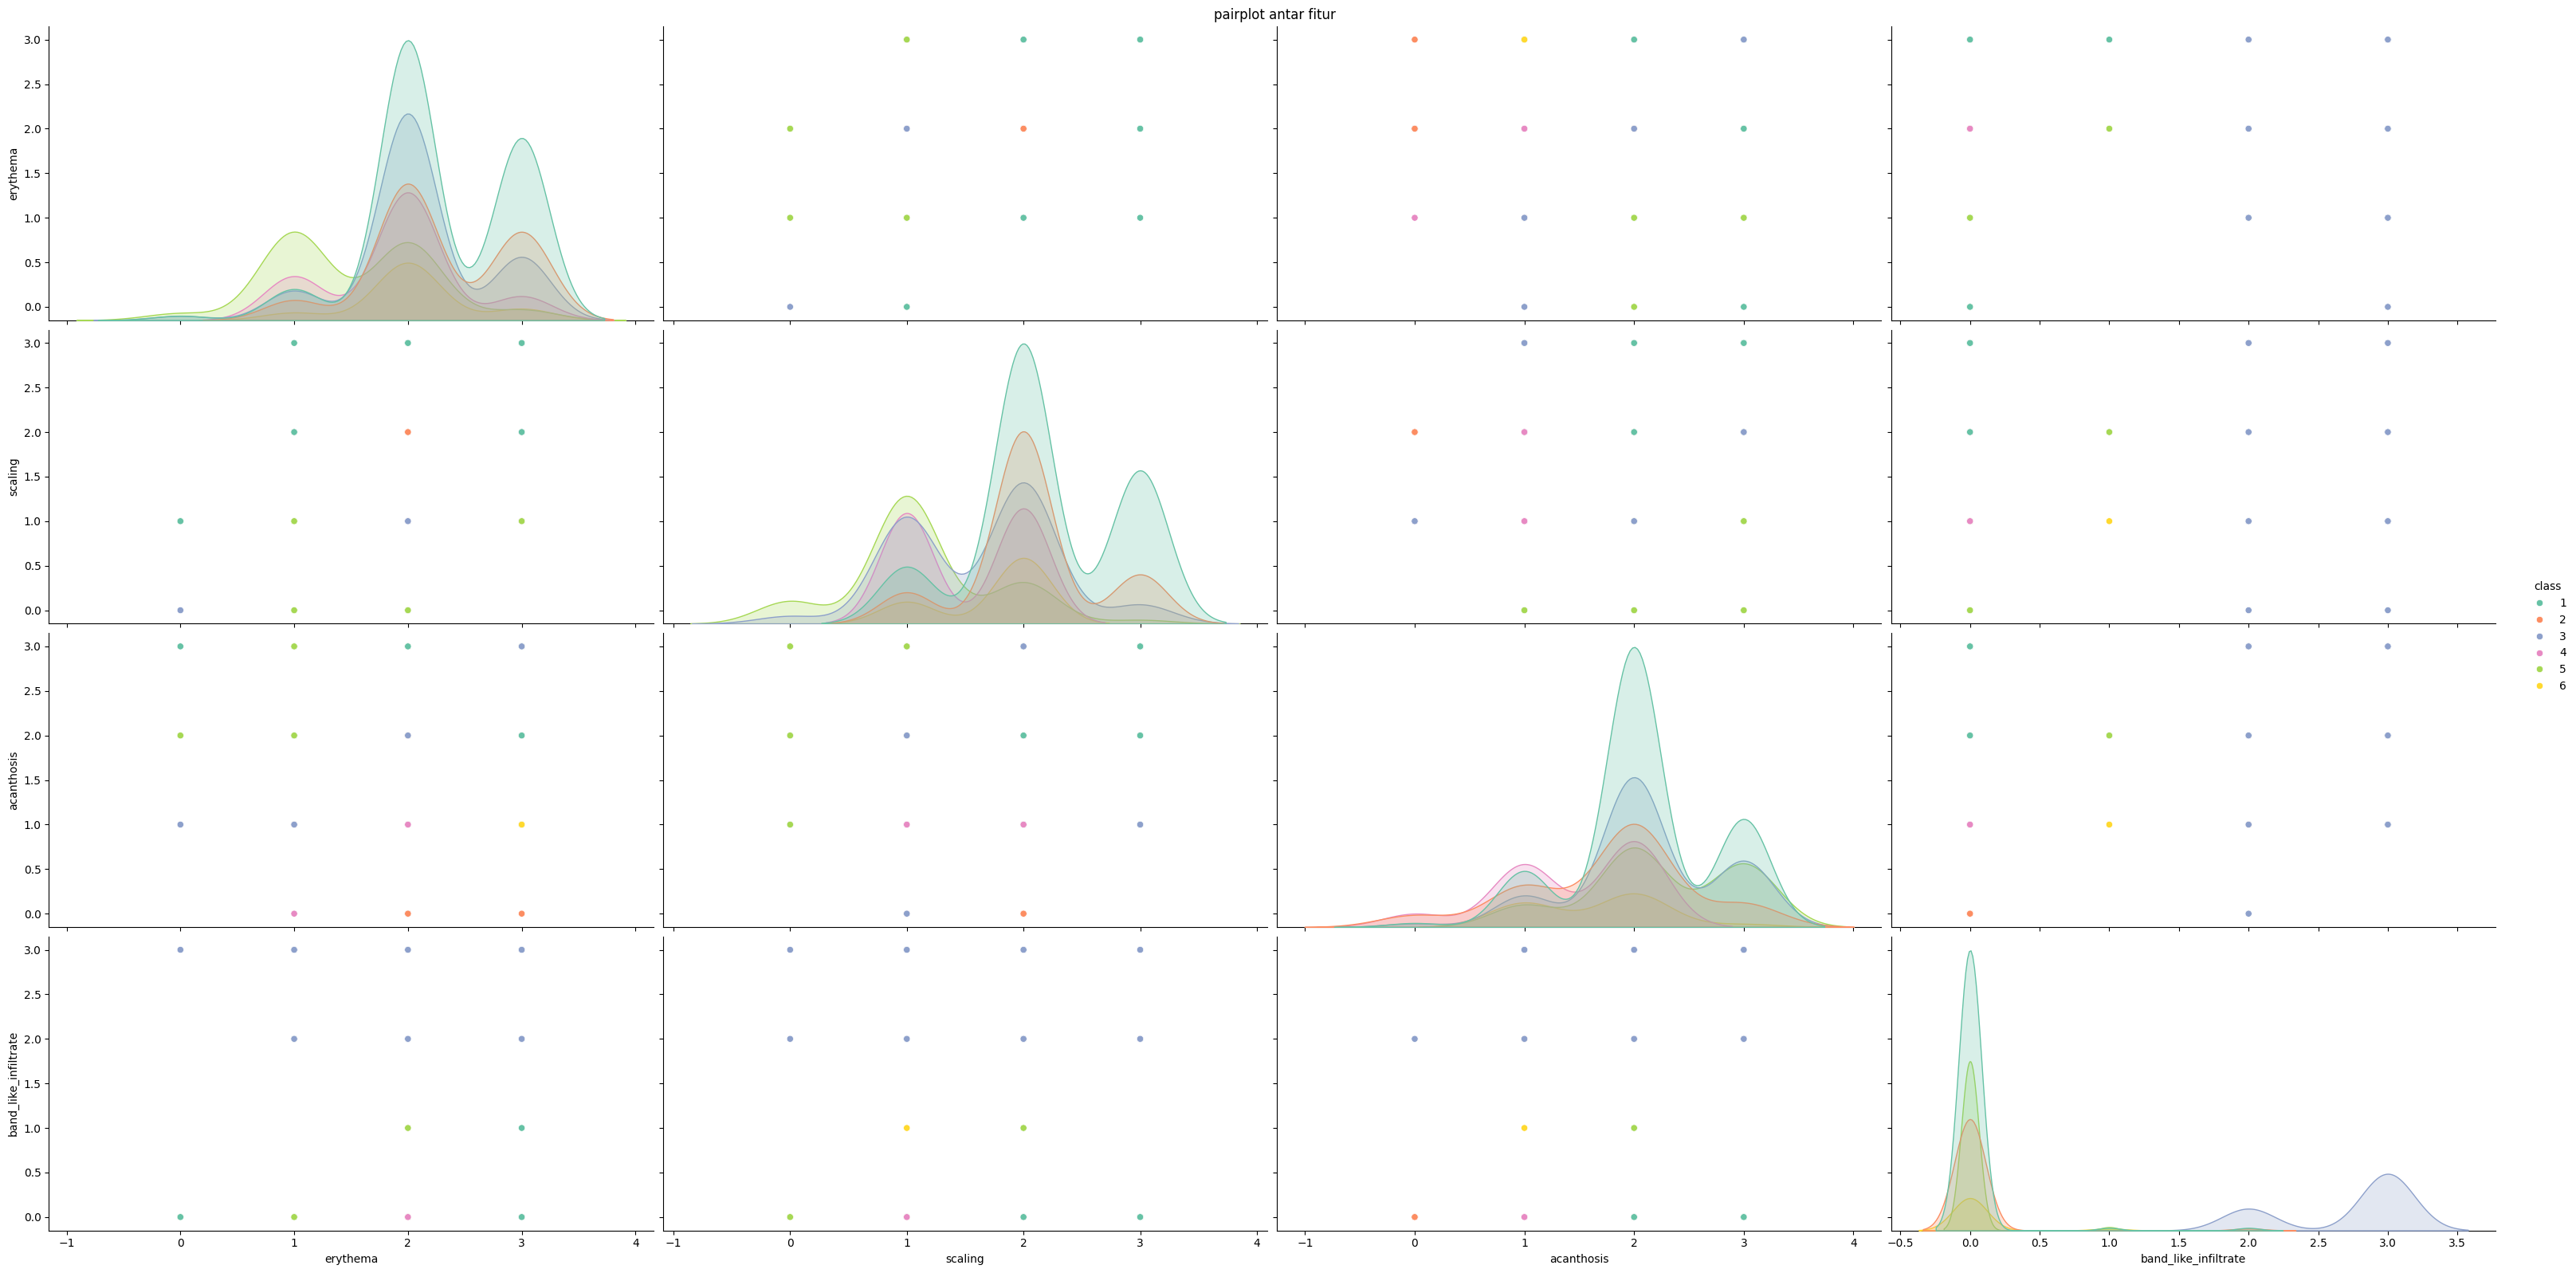

In [9]:
fitur = ['erythema','scaling','definite_borders','itching','koebner_phenomenon','polygonal_papules','follicular_papules','oral_mucosal_involvement','knee_and_elbow_involvement','scalp_involvement','family_history','melanin_incontinence','eosinophils_infiltrate','PNL_infiltrate','fibrosis_papillary_dermis','exocytosis','acanthosis','hyperkeratosis','parakeratosis','clubbing_rete_ridges','elongation_rete_ridges','thinning_suprapapillary_epidermis','spongiform_pustule','munro_microabcess','focal_hypergranulosis','disappearance_granular_layer','vacuolisation_damage_basal_layer','spongiosis','saw_tooth_appearance_retes','follicular_horn_plug','perifollicular_parakeratosis','inflammatory_mononuclear_infiltrate','band_like_infiltrate','age','class']

fitur_only = fitur[:-1]
grup = [list(x) for x in np.array_split(fitur_only, 3)]

for i, g in enumerate(grup):
    fig, axes = plt.subplots(3, 4, figsize = (30,30))
    for ax, col in zip(axes.flatten(), g):
        sns.boxplot(data = df, x = 'class', y=col, ax=ax, palette='Set3', legend = True)
        ax.set_title(col)
        for ax in axes.flatten()[len(g):]:
            ax.set_visible(False)
plt.suptitle(f'boxplot grup{i+1}', fontsize=12)
plt.tight_layout()
plt.show()

fitur_pairplot = ['erythema', 'scaling', 'acanthosis', 'age', 'band_like_infiltrate', 'class']

sns.pairplot(df[fitur_pairplot], hue = 'class', palette='Set2', height = 4, aspect=2)
plt.suptitle('pairplot antar fitur', y = 1, fontsize = 12)
plt.show()

# preprocessing

In [10]:

df = pd.read_csv('dermatology_database.csv', na_values='?')
imputer = SimpleImputer(strategy='median')
df['age'] = imputer.fit_transform(df[['age']])


In [ ]:
X = df.drop(columns='class')
y = df['class']

le = LabelEncoder()
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = le.fit_transform(X[col])
y_encoded = le.fit_transform(y)

sc = StandardScaler()
X = X.copy()
X['age'] = sc.fit_transform(X[['age']])


X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(type(X_train))   
print(X_train.shape)   

print(X_train.head()) 

<class 'pandas.core.frame.DataFrame'>
(292, 34)
     erythema  scaling  definite_borders  itching  koebner_phenomenon  \
215         2        3                 2        3                   3   
299         2        2                 1        3                   0   
148         2        2                 2        0                   2   
270         2        2                 1        0                   1   
331         1        1                 1        0                   1   

     polygonal_papules  follicular_papules  oral_mucosal_involvement  \
215                  2                   0                         2   
299                  0                   0                         0   
148                  0                   0                         0   
270                  0                   0                         0   
331                  0                   0                         0   

     knee_and_elbow_involvement  scalp_involvement  ...  \
215                  

In [12]:
print(type(X_train))
print(X_train.shape)

print(type(X))        # harus <class 'pandas.core.frame.DataFrame'>
print(X.shape)  

<class 'pandas.core.frame.DataFrame'>
(292, 34)
<class 'pandas.core.frame.DataFrame'>
(366, 34)


In [13]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print(pd.Series(y_train_sm).value_counts().sort_index())

0    89
1    89
2    89
3    89
4    89
5    89
Name: count, dtype: int64


# model

model: rf
accuracy: 0.9595
              precision    recall  f1-score   support

     Kelas 1       1.00      1.00      1.00        23
     Kelas 2       0.91      0.83      0.87        12
     Kelas 3       1.00      1.00      1.00        15
     Kelas 4       0.90      0.90      0.90        10
     Kelas 5       1.00      1.00      1.00        10
     Kelas 6       0.80      1.00      0.89         4

    accuracy                           0.96        74
   macro avg       0.93      0.96      0.94        74
weighted avg       0.96      0.96      0.96        74



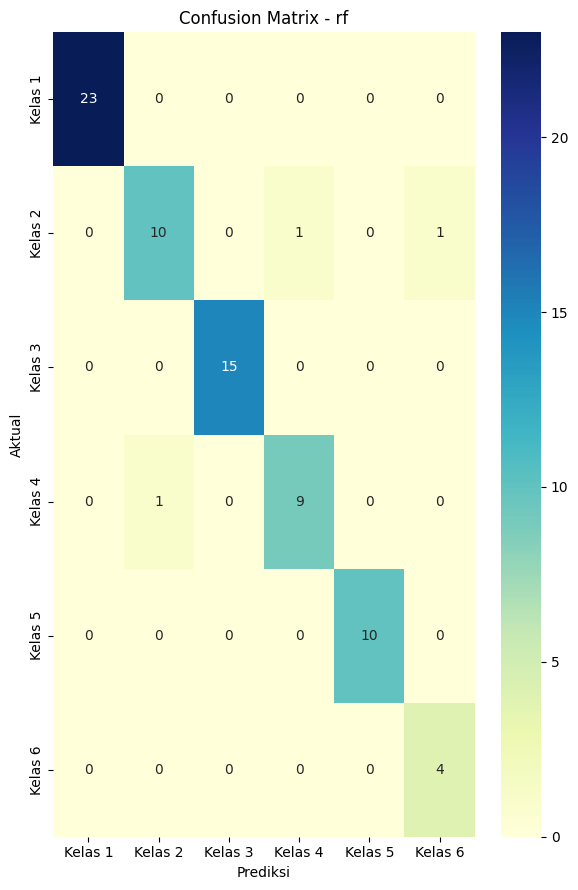

model: xgbost
accuracy: 0.9189
              precision    recall  f1-score   support

     Kelas 1       1.00      1.00      1.00        23
     Kelas 2       0.89      0.67      0.76        12
     Kelas 3       1.00      0.93      0.97        15
     Kelas 4       0.69      0.90      0.78        10
     Kelas 5       0.91      1.00      0.95        10
     Kelas 6       1.00      1.00      1.00         4

    accuracy                           0.92        74
   macro avg       0.92      0.92      0.91        74
weighted avg       0.93      0.92      0.92        74



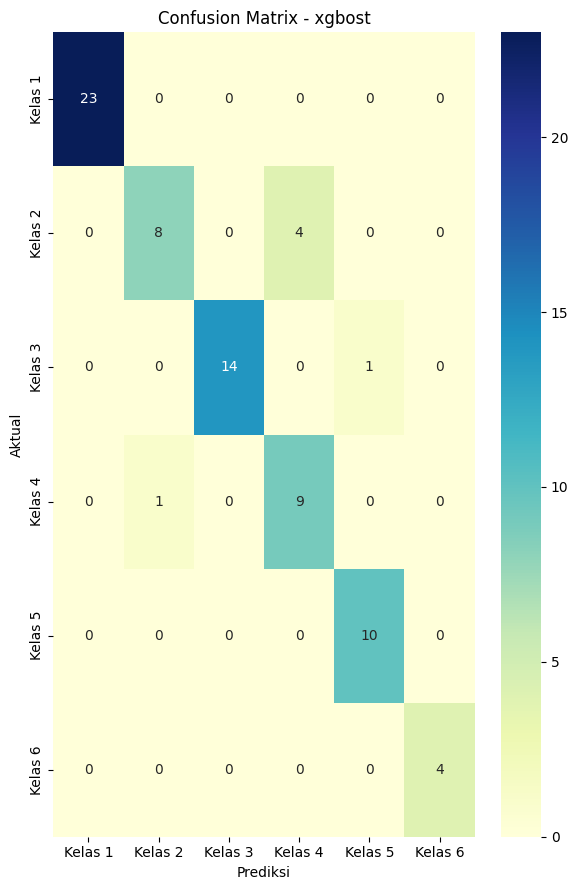

model: svm
accuracy: 0.9730
              precision    recall  f1-score   support

     Kelas 1       1.00      1.00      1.00        23
     Kelas 2       0.92      0.92      0.92        12
     Kelas 3       1.00      1.00      1.00        15
     Kelas 4       0.90      0.90      0.90        10
     Kelas 5       1.00      1.00      1.00        10
     Kelas 6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.97      0.97      0.97        74



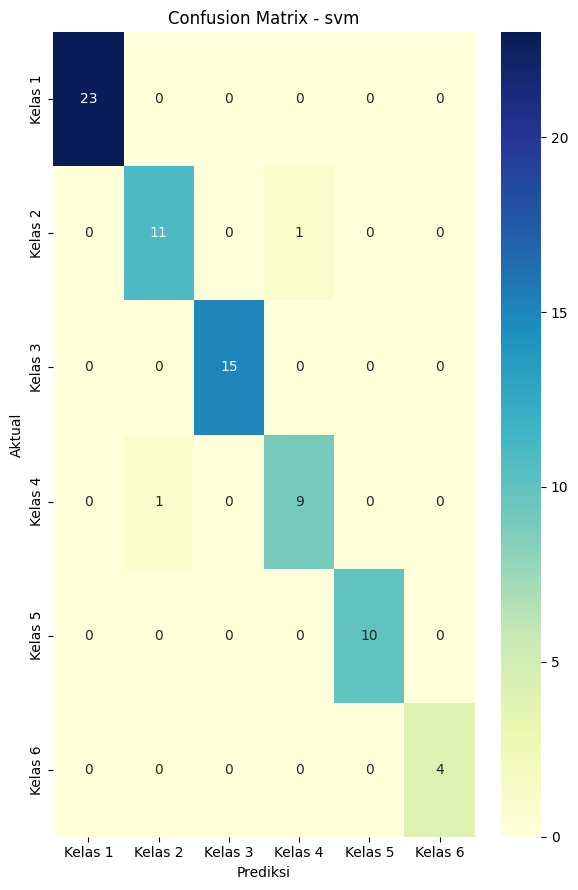

model: knn
accuracy: 0.9189
              precision    recall  f1-score   support

     Kelas 1       1.00      1.00      1.00        23
     Kelas 2       0.88      0.58      0.70        12
     Kelas 3       1.00      1.00      1.00        15
     Kelas 4       0.64      0.90      0.75        10
     Kelas 5       1.00      1.00      1.00        10
     Kelas 6       1.00      1.00      1.00         4

    accuracy                           0.92        74
   macro avg       0.92      0.91      0.91        74
weighted avg       0.93      0.92      0.92        74



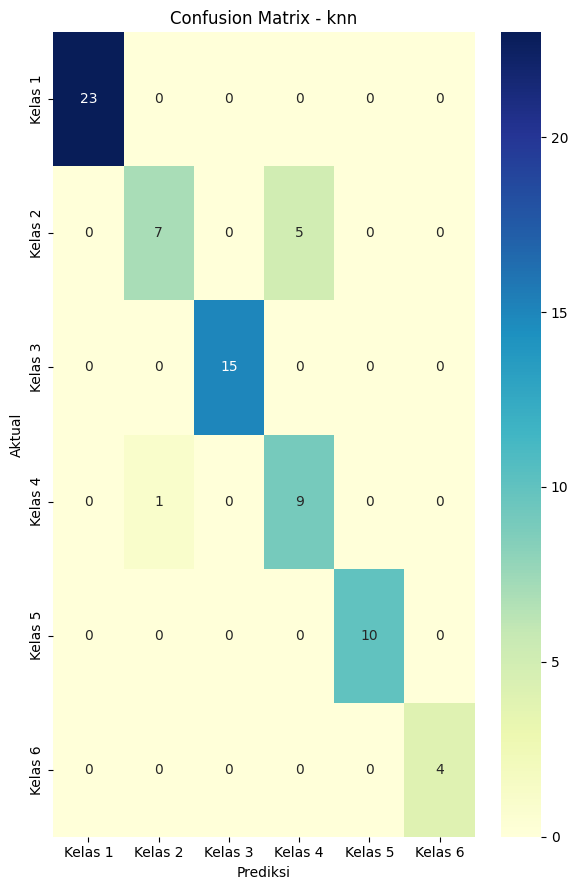

model: lr
accuracy: 0.9459
              precision    recall  f1-score   support

     Kelas 1       1.00      1.00      1.00        23
     Kelas 2       0.91      0.83      0.87        12
     Kelas 3       1.00      0.93      0.97        15
     Kelas 4       0.75      0.90      0.82        10
     Kelas 5       1.00      1.00      1.00        10
     Kelas 6       1.00      1.00      1.00         4

    accuracy                           0.95        74
   macro avg       0.94      0.94      0.94        74
weighted avg       0.95      0.95      0.95        74



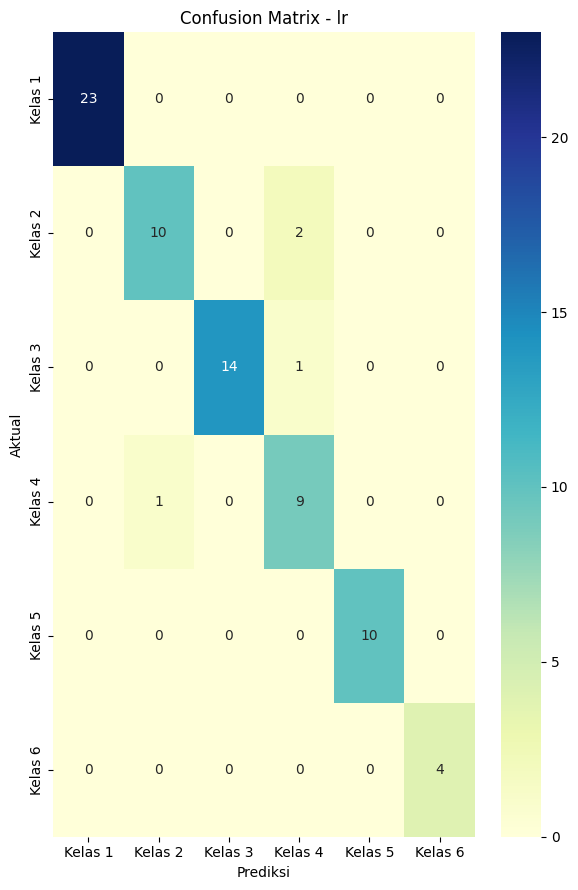

In [14]:
models = {
    'rf' : RandomForestClassifier(n_estimators=100, class_weight='balanced'),
    'xgbost' : XGBClassifier(random_state=42,
    objective='multi:softmax',
    num_class=6,
    eval_metric='mlogloss'),
    'svm' : SVC(kernel='rbf', probability=True),
    'knn' :KNeighborsClassifier(n_neighbors=7),
    'lr' : LogisticRegression(max_iter=1000)
}

for nama, model in models.items():
    model.fit(X_train_sm, y_train_sm)
    y_pred = model.predict(X_test)

    print('='*50)
    print(f'model: {nama}')
    print(f'accuracy: {accuracy_score(y_test, y_pred):.4f}')
    print(classification_report(y_test, y_pred, target_names= [f'Kelas {i+1}' for i in range(6)]))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,9))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
                xticklabels=[f'Kelas {i+1}' for i in range(6)],
                yticklabels=[f'Kelas {i+1}' for i in range(6)])
    plt.title(f'Confusion Matrix - {nama}')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()



# evaluasi model

perbandingan akurasi
svm                 : 97.30%
rf                  : 95.95%
lr                  : 94.59%
xgbost              : 91.89%
knn                 : 91.89%


C:\Users\evans\AppData\Local\Temp\ipykernel_22148\29056027.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(hasil.keys()), y=list(hasil.values()), palette='Set2')


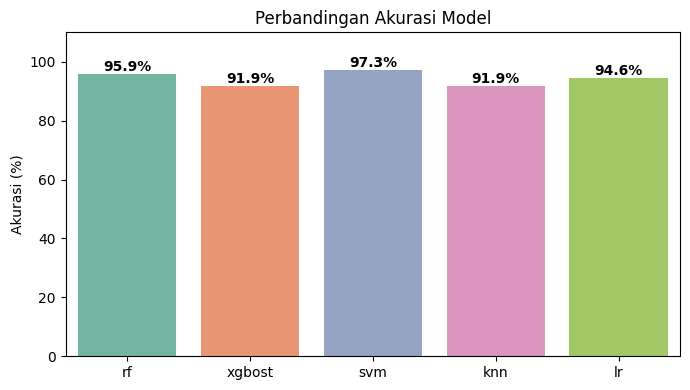

In [15]:
hasil = {}
for nama, model in models.items():
    y_pred = model.predict(X_test)
    hasil[nama] = accuracy_score(y_test, y_pred) * 100

print('perbandingan akurasi')
for nama, acc in sorted(hasil.items(), key=lambda x: -x[1]):
    print(f"{nama:<20}: {acc:.2f}%")

plt.figure(figsize=(7, 4))
sns.barplot(x=list(hasil.keys()), y=list(hasil.values()), palette='Set2') 
plt.ylim(0, 110)
plt.ylabel("Akurasi (%)")
plt.title("Perbandingan Akurasi Model")
for i, (nama, acc) in enumerate(hasil.items()):
    plt.text(i, acc + 1, f"{acc:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

# prediksi data baru

In [16]:
data_baru = pd.DataFrame([
    # er  sc  db  it  kp  pp  fp  om  ke  si  fh  mi  ei  pn  fi  ex  ac  hk  pk  cr  er2 ts  sp  mm  fh2 dg  vd  so  sr  fhp pp2 im  bl  age
    [2,  2,  2,  3,  0,  0,  0,  0,  1,  0,  0,  0,  0,  0,  0,  3,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  3,  0,  0,  0,  1,  0,  55],
    [3,  3,  3,  2,  1,  0,  0,  0,  1,  1,  1,  0,  0,  1,  0,  1,  2,  0,  2,  2,  2,  2,  2,  1,  0,  0,  0,  0,  0,  0,  0,  1,  0,  8],
    [0,  0,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  3,  0,  3,  0,  3,  0,  0,  0,  3,  35],
    [1,  1,  1,  1,  0,  0,  0,  0,  0,  1,  0,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  0,  0,  1,  1,  1,  1,  1,  0,  0,  1,  0,  42],
    [3,  2,  1,  2,  1,  3,  0,  3,  0,  0,  0,  1,  0,  0,  0,  2,  3,  1,  3,  0,  0,  0,  0,  0,  2,  0,  2,  2,  2,  0,  0,  2,  3,  26],
], columns=X.columns)

# Scaling kolom age seperti data training
data_baru['age'] = sc.transform(data_baru[['age']])

print(data_baru)

nama_kelas = {
    0: 'Psoriasis',
    1: 'Seboreik dermatitis',
    2: 'Lichen planus',
    3: 'Pityriasis rosea',
    4: 'Dermatitis kronis',
    5: 'Pityriasis rubra'
}

for nama, model in models.items():
    pred = model.predict(data_baru)
    print(f"\nModel: {nama}")
    for i, p in enumerate(pred):
        print(f"  Data {i+1}: Kelas {p+1} = {nama_kelas[p]}")

   erythema  scaling  definite_borders  itching  koebner_phenomenon  \
0         2        2                 2        3                   0   
1         3        3                 3        2                   1   
2         0        0                 2        0                   0   
3         1        1                 1        1                   0   
4         3        2                 1        2                   1   

   polygonal_papules  follicular_papules  oral_mucosal_involvement  \
0                  0                   0                         0   
1                  0                   0                         0   
2                  0                   0                         0   
3                  0                   0                         0   
4                  3                   0                         3   

   knee_and_elbow_involvement  scalp_involvement  ...  focal_hypergranulosis  \
0                           1                  0  ...                   